# Statistical estimation: fitted values are only the beginning

This notebook inspects parameter recovery, uncertainty, sensitivity to contamination, and constraints. We generate the data so the underlying parameters are visible, but a fitted estimate need not equal them in a finite sample.

Convexity's estimation objects expose the objective, parameter coordinates, and uncertainty assumptions. We will compare these with quantities the experiment actually identifies. [Estimation contracts](../statistical_estimation.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import distributions as dist, estimation as est

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## Fit a law and inspect its parameters

The model is $Y\sim N(\mu,\sigma^2)$. We optimize `(mu, log_sigma)`, so the scale remains positive without clipping. `est.likelihood` composes a parameter-to-distribution function with the observations; `maximum_likelihood` maximizes the complete log likelihood.

The analytic MLE is a useful reference for this particular model. Agreement with it establishes numerical accuracy; proximity to the generating parameters measures sampling error. Those are different sources of error.

In [2]:
sample = dist.normal(2.0, 1.5).sample(500, rng=rng)
model = est.likelihood(lambda t: dist.normal(t[0], np.exp(t[1])), sample)
space = est.ParameterSpace([0.0, 0.0], names=('mu', 'log_sigma'))
mle = est.maximum_likelihood(model, space)
closed_form = np.array([sample.mean(), np.log(sample.std())])
pd.DataFrame({'numerical MLE': mle.parameters, 'analytic MLE': closed_form, 'standard error': mle.standard_errors}, index=mle.names)

,numerical MLE,analytic MLE,standard error
mu,1.980306,1.980311,0.064330
log_sigma,0.363577,0.363573,0.031623


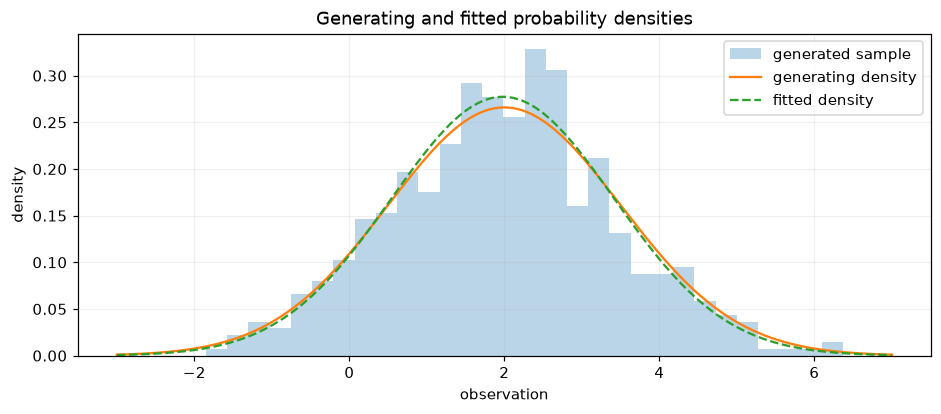

In [3]:
grid = np.linspace(-3, 7, 400)
fitted_law = dist.normal(mle.parameters[0], np.exp(mle.parameters[1]))
fig, ax = plt.subplots()
ax.hist(sample, bins=30, density=True, alpha=0.3, label='generated sample')
ax.plot(grid, dist.normal(2, 1.5).density(grid), label='generating density')
ax.plot(grid, fitted_law.density(grid), '--', label='fitted density')
ax.set(xlabel='observation', ylabel='density', title='Generating and fitted probability densities')
ax.legend()
plt.show()

## Parameter coordinates change uncertainty statements

The inverse observed information describes local sampling uncertainty in `(mu, log_sigma)`. A Wald interval is symmetric in those coordinates. Exponentiating an interval for `log_sigma` gives an asymmetric interval for `sigma`.

`delta_method` instead propagates the covariance through a first-order derivative. Compare its symmetric scale interval with the transformed log-scale interval. Neither is a prediction interval for a new observation.

In [4]:
coordinate_interval = est.wald_interval(mle)
scale_estimate = est.delta_method(mle, lambda p: np.exp(p[1]), names=("sigma",))
scale_interval = est.wald_interval(scale_estimate)
pd.DataFrame({"estimate": [np.exp(mle.parameters[1]), scale_estimate.parameters[0]],
              "lower 95%": [np.exp(coordinate_interval.lower[1]), scale_interval.lower[0]],
              "upper 95%": [np.exp(coordinate_interval.upper[1]), scale_interval.upper[0]]},
             index=["Exponentiated log-scale interval", "Delta-method scale interval"])

,estimate,lower 95%,upper 95%
Exponentiated log-scale interval,1.438466,1.352017,1.530442
Delta-method scale interval,1.438466,1.349310,1.527621


## A prior matters most when data are scarce

Now hold the observation standard deviation at 1.5 and estimate only the mean from twelve observations. A $N(0,1)$ prior pulls the posterior mean toward zero. Here conjugacy makes the Gaussian posterior exact, so the MAP and posterior mean agree. In a general model, a MAP estimate and a local Laplace approximation do not describe the full posterior.

In [5]:
small = sample[:12]
known_scale = est.likelihood(lambda t: dist.normal(t[0], 1.5), small)
posterior = est.maximum_a_posteriori(known_scale, est.gaussian_prior(0.0, 1.0), [0.0])
posterior_variance = 1 / (len(small) / 1.5 ** 2 + 1)
posterior_mean = posterior_variance * small.sum() / 1.5 ** 2
credible = est.laplace_interval(posterior)
pd.DataFrame({"MAP / posterior mean": posterior.parameters,
              "conjugate reference mean": [posterior_mean],
              "lower 95% credible": credible.lower, "upper 95% credible": credible.upper}, index=["Mean"])

,MAP / posterior mean,conjugate reference mean,lower 95% credible,upper 95% credible
Mean,1.505419,1.505419,0.726608,2.284229


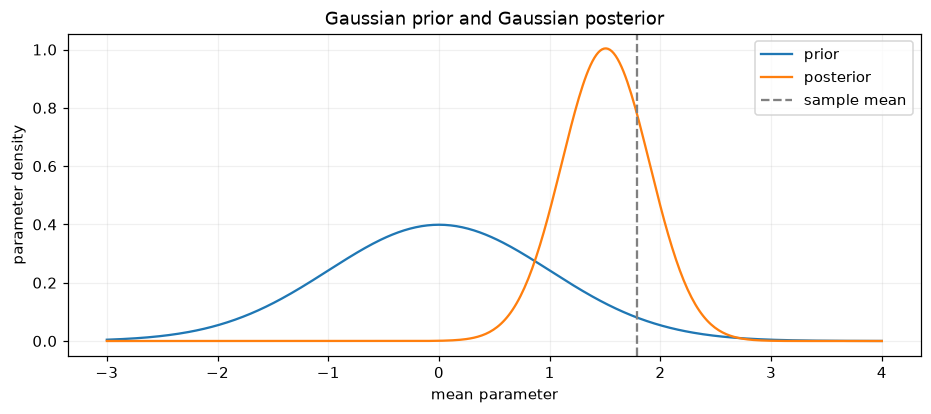

In [6]:
u = np.linspace(-3, 4, 400)
fig, ax = plt.subplots()
ax.plot(u, dist.normal(0, 1).density(u), label='prior')
ax.plot(u, dist.normal(posterior_mean, np.sqrt(posterior_variance)).density(u), label='posterior')
ax.axvline(small.mean(), color='gray', linestyle='--', label='sample mean')
ax.set(xlabel='mean parameter', ylabel='parameter density', title='Gaussian prior and Gaussian posterior')
ax.legend()
plt.show()

## Nonlinear recovery: inspect residuals as well as the curve

The decay model is $y(t)=a e^{-bt}+\epsilon$, with known observation standard deviation 0.04. Dividing residuals by that scale gives the intended least-squares weighting; `absolute_sigma=True` retains it for uncertainty calculations.

A good fitted curve should leave residuals centred around zero without a systematic time pattern. A small residual alone cannot identify two parameters whose effects are nearly indistinguishable.

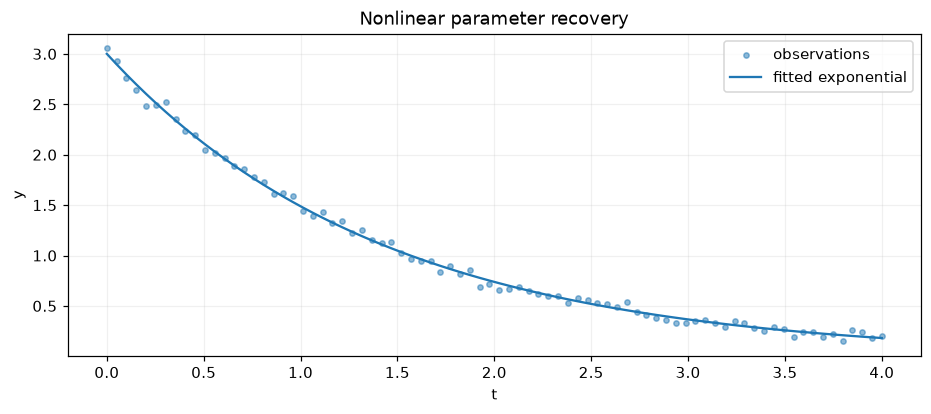

In [7]:
t = np.linspace(0, 4, 80)
y = 3 * np.exp(-0.7 * t) + rng.normal(0, 0.04, len(t))
decay = est.least_squares(lambda p: (p[0] * np.exp(-p[1] * t) - y) / 0.04, est.ParameterSpace([2.0, 0.5], names=('amplitude', 'decay'), lower=0.0), absolute_sigma=True)
fig, ax = plt.subplots()
ax.scatter(t, y, s=12, alpha=0.5, label='observations')
ax.plot(t, decay.parameters[0] * np.exp(-decay.parameters[1] * t), label='fitted exponential')
ax.set(xlabel='t', ylabel='y', title='Nonlinear parameter recovery')
ax.legend()
plt.show()

,generating value,estimate,lower 95%,upper 95%
amplitude,3.0,3.000831,2.971712,3.029950
decay,0.7,0.701172,0.690980,0.711364


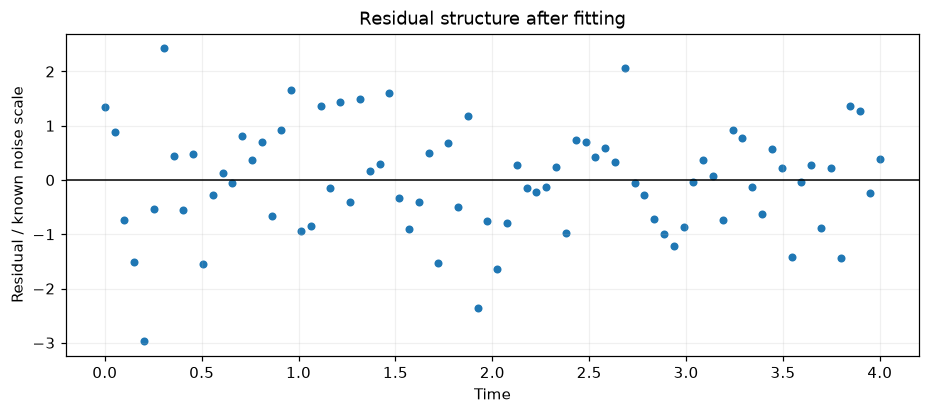

In [8]:
decay_interval = est.wald_interval(decay)
display(pd.DataFrame({"generating value": [3., .7], "estimate": decay.parameters,
    "lower 95%": decay_interval.lower, "upper 95%": decay_interval.upper}, index=decay.names))
fig, ax = plt.subplots()
ax.scatter(t, (y-decay.parameters[0]*np.exp(-decay.parameters[1]*t))/.04, s=18)
ax.axhline(0, color="black", linewidth=1)
ax.set(xlabel="Time", ylabel="Residual / known noise scale", title="Residual structure after fitting")
plt.show()

## Precision weights should describe the experiment

We now generate a line with measurement noise that increases with $|x|$. Weighted least squares uses the known inverse variances, rather than arbitrary weights applied to homoskedastic data. OLS remains a mean estimator; HC3 changes its covariance estimate, not its fitted coefficients.

Inspect the parameter table and the visible noise envelope. WLS can improve precision when its variance model is correct. HC3 does not repair an incorrect mean function or dependent errors.

,truth,OLS,WLS,OLS SE,HC3 SE,WLS SE
intercept,1.0,0.922339,0.966591,0.037113,0.037540,0.022109
slope,2.0,1.992653,1.983325,0.031940,0.043524,0.035500


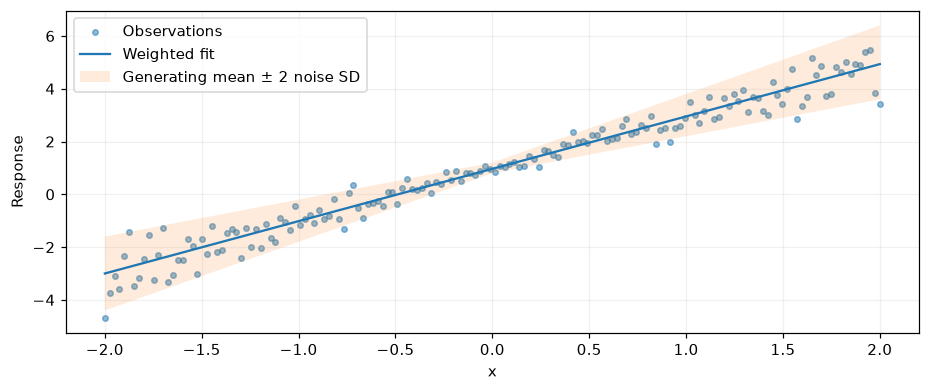

In [9]:
x = np.linspace(-2, 2, 160)
X = np.column_stack((np.ones(len(x)), x))
noise_scale = .1 + .3*np.abs(x)
y_linear = X @ [1., 2.] + rng.normal(size=len(x))*noise_scale
ols = est.linear_least_squares(X, y_linear, names=("intercept", "slope"))
wls = est.linear_least_squares(X, y_linear, weights=1/noise_scale**2, names=ols.names)
hc3 = est.linear_least_squares(X, y_linear, covariance_type="HC3", names=ols.names)
display(pd.DataFrame({"truth": [1., 2.], "OLS": ols.parameters, "WLS": wls.parameters,
    "OLS SE": ols.standard_errors, "HC3 SE": hc3.standard_errors, "WLS SE": wls.standard_errors}, index=ols.names))
fig, ax = plt.subplots()
ax.scatter(x, y_linear, s=13, alpha=.5, label="Observations")
ax.plot(x, X @ wls.parameters, label="Weighted fit")
ax.fill_between(x, X @ [1., 2.]-2*noise_scale, X @ [1., 2.]+2*noise_scale, alpha=.15, label="Generating mean ± 2 noise SD")
ax.set(xlabel="x", ylabel="Response")
ax.legend()
plt.show()

## Contamination changes which loss is useful

Add large response errors at the largest input values. Their leverage makes ordinary least squares particularly sensitive. Huber limits large residual influence; Tukey can downweight it more aggressively.

The unobserved generating line is available only because this is a simulation. In an application, a disagreement between losses is a reason to inspect the data and assumptions, not proof that one estimator is right.

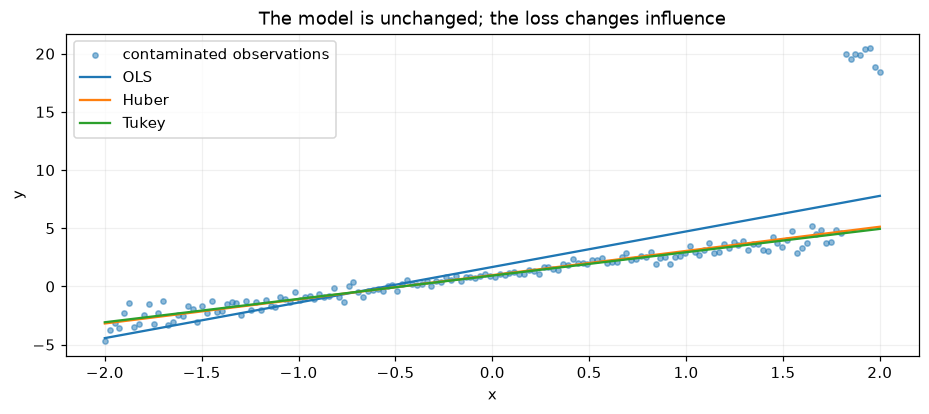

,truth,OLS,Huber,Tukey
intercept,1.0,1.672339,0.974090,0.935508
slope,2.0,3.054765,2.077701,2.005569


In [10]:
contaminated = y_linear.copy()
contaminated[-8:] += 15
ordinary = est.linear_least_squares(X, contaminated)
huber = est.robust_linear(X, contaminated)
tukey = est.robust_linear(X, contaminated, loss='tukey')
fig, ax = plt.subplots()
ax.scatter(x, contaminated, s=12, alpha=0.5, label='contaminated observations')
for label, estimate in [('OLS', ordinary), ('Huber', huber), ('Tukey', tukey)]:
    ax.plot(x, X @ estimate.parameters, label=label)
ax.set(xlabel='x', ylabel='y', title='The model is unchanged; the loss changes influence')
ax.legend()
plt.show()
pd.DataFrame({'truth': [1.0, 2.0], 'OLS': ordinary.parameters, 'Huber': huber.parameters, 'Tukey': tukey.parameters}, index=['intercept', 'slope'])

## Shrinkage and constraints encode different preferences

The orthogonal design isolates the effect of ridge, lasso, and elastic-net penalties. Ridge shrinks continuously; lasso can set small coefficients to zero. Penalized coefficients do not automatically carry ordinary unpenalized standard errors.

The second example imposes $a+b=1$ and box bounds. That is a feasible-set restriction, not a penalty selected from data. The contour plot shows how the unconstrained and constrained optima differ.

In [11]:
z = np.array([3.0, -0.2, -1.0, 0.0])
orthogonal = np.sqrt(4) * np.eye(4)
alpha = 0.4
fits = {}
for label, ratio in [('ridge', 0.0), ('elastic net', 0.5), ('lasso', 1.0)]:
    fitted = est.regularized_linear(orthogonal, orthogonal @ z, alpha=alpha, l1_ratio=ratio)
    fits[label] = fitted.parameters
pd.DataFrame({'unpenalized': z, **fits})

,unpenalized,ridge,elastic net,lasso
0,3.0,2.142857,2.333333,2.6
1,-0.2,-0.142857,-0.000000,-0.0
2,-1.0,-0.714286,-0.666667,-0.6
3,0.0,0.000000,0.000000,0.0


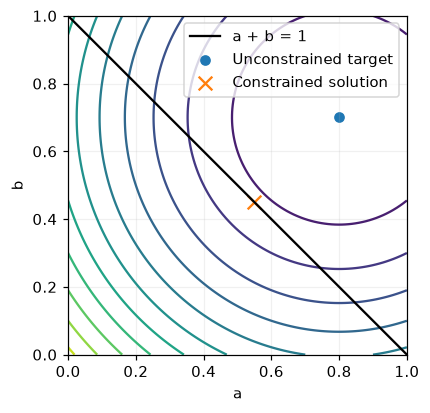

In [12]:
constrained = est.minimize_estimate(lambda p: np.sum((p-[.8, .7])**2),
    est.ParameterSpace([.5, .5], names=("a", "b"), lower=0., upper=1.),
    constraints=[est.LinearConstraint([[1., 1.]], lower=1., upper=1.)])
u = np.linspace(0, 1, 100)
aa, bb = np.meshgrid(u, u)
fig, ax = plt.subplots(figsize=(5, 4))
ax.contour(aa, bb, (aa-.8)**2+(bb-.7)**2, levels=12)
ax.plot(u, 1-u, color="black", label="a + b = 1")
ax.scatter([.8], [.7], label="Unconstrained target")
ax.scatter(*constrained.parameters, marker="x", s=80, label="Constrained solution")
ax.set(xlabel="a", ylabel="b", aspect="equal")
ax.legend()
plt.show()

## Resampling reveals the estimator's variability

Paired-row bootstrap resamples `(design row, response)` together. Keeping the pair matters: resampling each independently would destroy the regression relationship. The histograms below compare the bootstrap parameter draws with the point estimate and BCa intervals.

This is an IID-row resampling experiment. It does not justify resampling individual observations from an autocorrelated time series. Compare the bootstrap widths with HC3 standard errors above; they use different approximations to uncertainty.

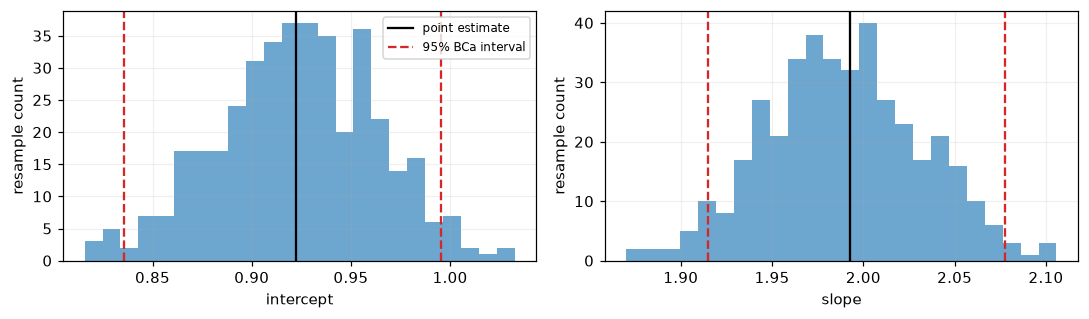

,OLS estimate,bootstrap standard error,HC3 standard error,lower 95% BCa,upper 95% BCa
intercept,0.922339,0.039806,0.037540,0.835511,0.995337
slope,1.992653,0.042868,0.043524,1.914743,2.077548


In [13]:
boot = est.bootstrap(lambda design, response: est.linear_least_squares(design, response, names=('intercept', 'slope')), (X, y_linear), rng=rng, method='BCa', n_resamples=399)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for j, ax in enumerate(axes):
    ax.hist(boot.draws[:, j], bins=24, alpha=0.65)
    ax.axvline(ols.parameters[j], color='black', label='point estimate')
    ax.axvline(boot.interval.lower[j], color='tab:red', linestyle='--', label='95% BCa interval')
    ax.axvline(boot.interval.upper[j], color='tab:red', linestyle='--')
    ax.set(xlabel=boot.estimate.names[j], ylabel='resample count')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame({"OLS estimate": ols.parameters,
              "bootstrap standard error": boot.draws.std(axis=0, ddof=1),
              "HC3 standard error": hc3.standard_errors,
              "lower 95% BCa": boot.interval.lower, "upper 95% BCa": boot.interval.upper}, index=ols.names)

To explore sensitivity, change the sample size, noise envelope, or contaminated fraction and rerun from the top. Keep the generating parameters visible so a numerical solver error is distinguishable from an estimator that is inappropriate for the data. Boundary estimates and custom estimators are covered in the [API guide](../statistical_estimation.md).